# 24 — De la base de datos a un mes predicho a ciegas

## Pregunta y alcance

Los cuadernos anteriores construyeron y validaron el modelo de pronóstico sobre series ya extraídas. Este cuaderno
recorre el camino completo en un solo lugar: se abre la conexión con la base clínica, se cuentan los registros de
triage de la tabla `DIM_TRIAGE`, se observa la serie a lo largo del tiempo y se somete el modelo vigente a una prueba
exigente: entrenado solo con datos hasta el 31 de diciembre de 2025, predice cada día de septiembre de 2026, ocho
meses después, sin ningún dato reciente en que apoyarse. Al final se compara lo anunciado con lo ocurrido, día por
día y semana por semana.

La pregunta es qué sabe el modelo del hospital cuando no puede copiar lo que pasó la semana anterior: si su acierto
viene de entender el calendario, la estación y el contexto, o solo de la cercanía de los datos.

## Contenido

1. La conexión con la base y el conteo de registros.
2. Los triages a lo largo del tiempo.
3. La prueba: entrenar hasta 2025 y predecir septiembre de 2026 completo.
4. Qué tan confiable es: el mismo diseño en septiembre de 2023, 2024 y 2025.
5. La predicción de septiembre de 2026.
6. Lo predicho frente a lo ocurrido.
7. Límites del análisis.

In [1]:
import os, sys, json, pathlib, warnings
RAIZ = next(p for p in [pathlib.Path.cwd(), *pathlib.Path.cwd().parents] if (p / "CLAUDE.md").exists())
sys.path[:0] = [str(RAIZ), str(RAIZ / "notebooks")]; warnings.filterwarnings("ignore")
import numpy as np, pandas as pd
from matplotlib import pyplot as plt
from IPython.display import Markdown, display

# Parámetros del cuaderno
FUENTE = os.environ.get("TRIAGE_FUENTE", "base")   # "base": SQL Server (DWSES); "archivo": salidas/triage_horario.parquet
ANIO = 2026                                         # septiembre de este año, con el modelo entrenado hasta el 31 de diciembre anterior

AZUL, NARANJA, AQUA, AMARILLO, MAGENTA, VERDE, VIOLETA, ROJO = (
    "#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#4a3aa7", "#e34948")
TINTA, TINTA2, MUDO, SUP = "#0b0b0b", "#52514e", "#898781", "#fcfcfb"
COLOR = {"M3s": AZUL, "C0r": NARANJA}
plt.rcParams.update({"figure.facecolor": SUP, "axes.facecolor": SUP, "axes.spines.top": False,
    "axes.spines.right": False, "axes.edgecolor": MUDO, "axes.grid": True, "grid.color": "#e6e5e1",
    "grid.linewidth": .6, "axes.labelcolor": TINTA2, "xtick.color": TINTA2, "ytick.color": TINTA2,
    "axes.titlesize": 11, "axes.titleweight": "bold", "axes.titlecolor": TINTA, "font.size": 10,
    "legend.frameon": False})
DIAS = ["lunes", "martes", "miércoles", "jueves", "viernes", "sábado", "domingo"]
MESES = ["", "enero", "febrero", "marzo", "abril", "mayo", "junio", "julio", "agosto", "septiembre", "octubre",
         "noviembre", "diciembre"]
num = lambda x, d=1: f"{x:,.{d}f}".replace(",", "§").replace(".", ",").replace("§", ".")
fecha_larga = lambda t: f"{DIAS[t.dayofweek]} {t.day} de {MESES[t.month]}"

---
# 1. La conexión con la base y el conteo de registros

La base clínica es `DWSES`, en el servidor SQL Server del hospital, y se consulta por ODBC con la autenticación de
Windows: no hay usuario ni contraseña escritos en ningún archivo. La conexión la abre `extraccion.motor()`, el único
módulo del repositorio que habla con SQL Server.

El acceso sigue un protocolo de tres pasos que impide que salga dato personal:

1. **Mirar el esquema primero.** `INFORMATION_SCHEMA.COLUMNS` describe las columnas sin devolver ni una fila de
   datos.
2. **Clasificar las columnas.** Documento, nombres, médico y el texto libre del motivo de consulta se marcan como
   sensibles y no se consultan.
3. **Consultar solo agregados.** De `DIM_TRIAGE` se baja únicamente la fecha y la hora del triage (`HCTFECTRI`)
   contadas con `COUNT(*)` y `GROUP BY`. Ningún identificador sale de la base.

Si la conexión no está disponible (por ejemplo, fuera de la red del hospital), el cuaderno lo informa y lee
`salidas/triage_horario.parquet`, que es el resultado de la misma consulta guardado en la última extracción.

In [2]:
from extraccion import motor
import extraccion.__main__ as ex

eng = None
if FUENTE == "base":
    try:
        eng = motor()
        with eng.connect() as c:
            servidor, base = c.exec_driver_sql("SELECT @@SERVERNAME, DB_NAME()").fetchone()
        print(f"Conexión abierta: servidor {servidor}, base {base}.")
        print("\nPasos 1 y 2: columnas de las tablas del triage y su clasificación")
        ex.esquema(eng)
    except Exception as e:
        print(f"No se pudo abrir la conexión ({type(e).__name__}: {str(e)[:160]}).")
        FUENTE = "archivo"
if FUENTE == "archivo":
    print("Fuente de los conteos: salidas/triage_horario.parquet (la misma consulta, guardada en la última extracción).")

Fuente de los conteos: salidas/triage_horario.parquet (la misma consulta, guardada en la última extracción).


In [3]:
if FUENTE == "base":
    print("Paso 3: la consulta agregada que se ejecuta\n" + ex.SQL_CONTEO_HORARIO)
    hora = ex.conteo_horario(eng)
else:
    hora = pd.read_parquet(RAIZ / "salidas/triage_horario.parquet")
    hora["dia"] = pd.to_datetime(hora["dia"])

dia = hora.groupby("dia").triages.sum()
# El último día de una extracción suele estar a medias (la carga se corta en el día en curso): se descarta.
corte = dia.index.max()
serie = dia[dia.index < corte].astype(float)
serie = serie.reindex(pd.date_range(serie.index.min(), serie.index.max(), freq="D"))
# 19 y 20 de marzo de 2024 sin filas y 21 con el 17 % de lo esperado: caída del registro, no ausencia de pacientes
serie["2024-03-19":"2024-03-21"] = np.nan

display(pd.DataFrame({
    "": ["casillas día × hora leídas", "registros de triage contados", "primer día", "último día completo",
         "día descartado por incompleto", "días sin dato (caída de registro)"],
    "valor": [num(len(hora), 0), num(hora.triages.sum(), 0), str(serie.index.min().date()), str(serie.index.max().date()),
              f"{corte.date()} ({int(dia[corte])} registros)", int(serie.isna().sum())]}).set_index(""))

,valor
,
casillas día × hora leídas,55.844
registros de triage contados,433.392
primer día,2020-01-01
último día completo,2026-09-20
día descartado por incompleto,2026-09-21 (94 registros)
días sin dato (caída de registro),3


Antes de usar los conteos se comprueba que la base y la serie con que se entrenó el modelo cuentan lo mismo en los
días que comparten. Una diferencia indicaría registros cargados o corregidos después de la última extracción.

In [4]:
arch = pd.read_parquet(RAIZ / "salidas/triage_diario.parquet")
arch = arch.assign(dia=pd.to_datetime(arch.dia)).set_index("dia").triages.astype(float)
comun = serie.dropna().index.intersection(arch.index[arch.index < arch.index.max()])
dif = serie[comun] - arch[comun]
if FUENTE == "archivo":
    print("La fuente es el propio archivo de entrenamiento: la comparación no aplica.")
else:
    print(f"Días en común: {len(comun)}; con conteo distinto: {(dif != 0).sum()}; "
          f"diferencia total: {num(dif.sum(), 0)} registros ({num(100 * dif.sum() / arch[comun].sum(), 2)} %).")
    if (dif != 0).any():
        display(dif[dif != 0].rename("base − archivo").to_frame().tail(15))

La fuente es el propio archivo de entrenamiento: la comparación no aplica.


---
# 2. Los triages a lo largo del tiempo

El calendario de calor muestra un cuadro por día; el color es el número de registros de triage. Los días sin dato
quedan en gris, no en cero.

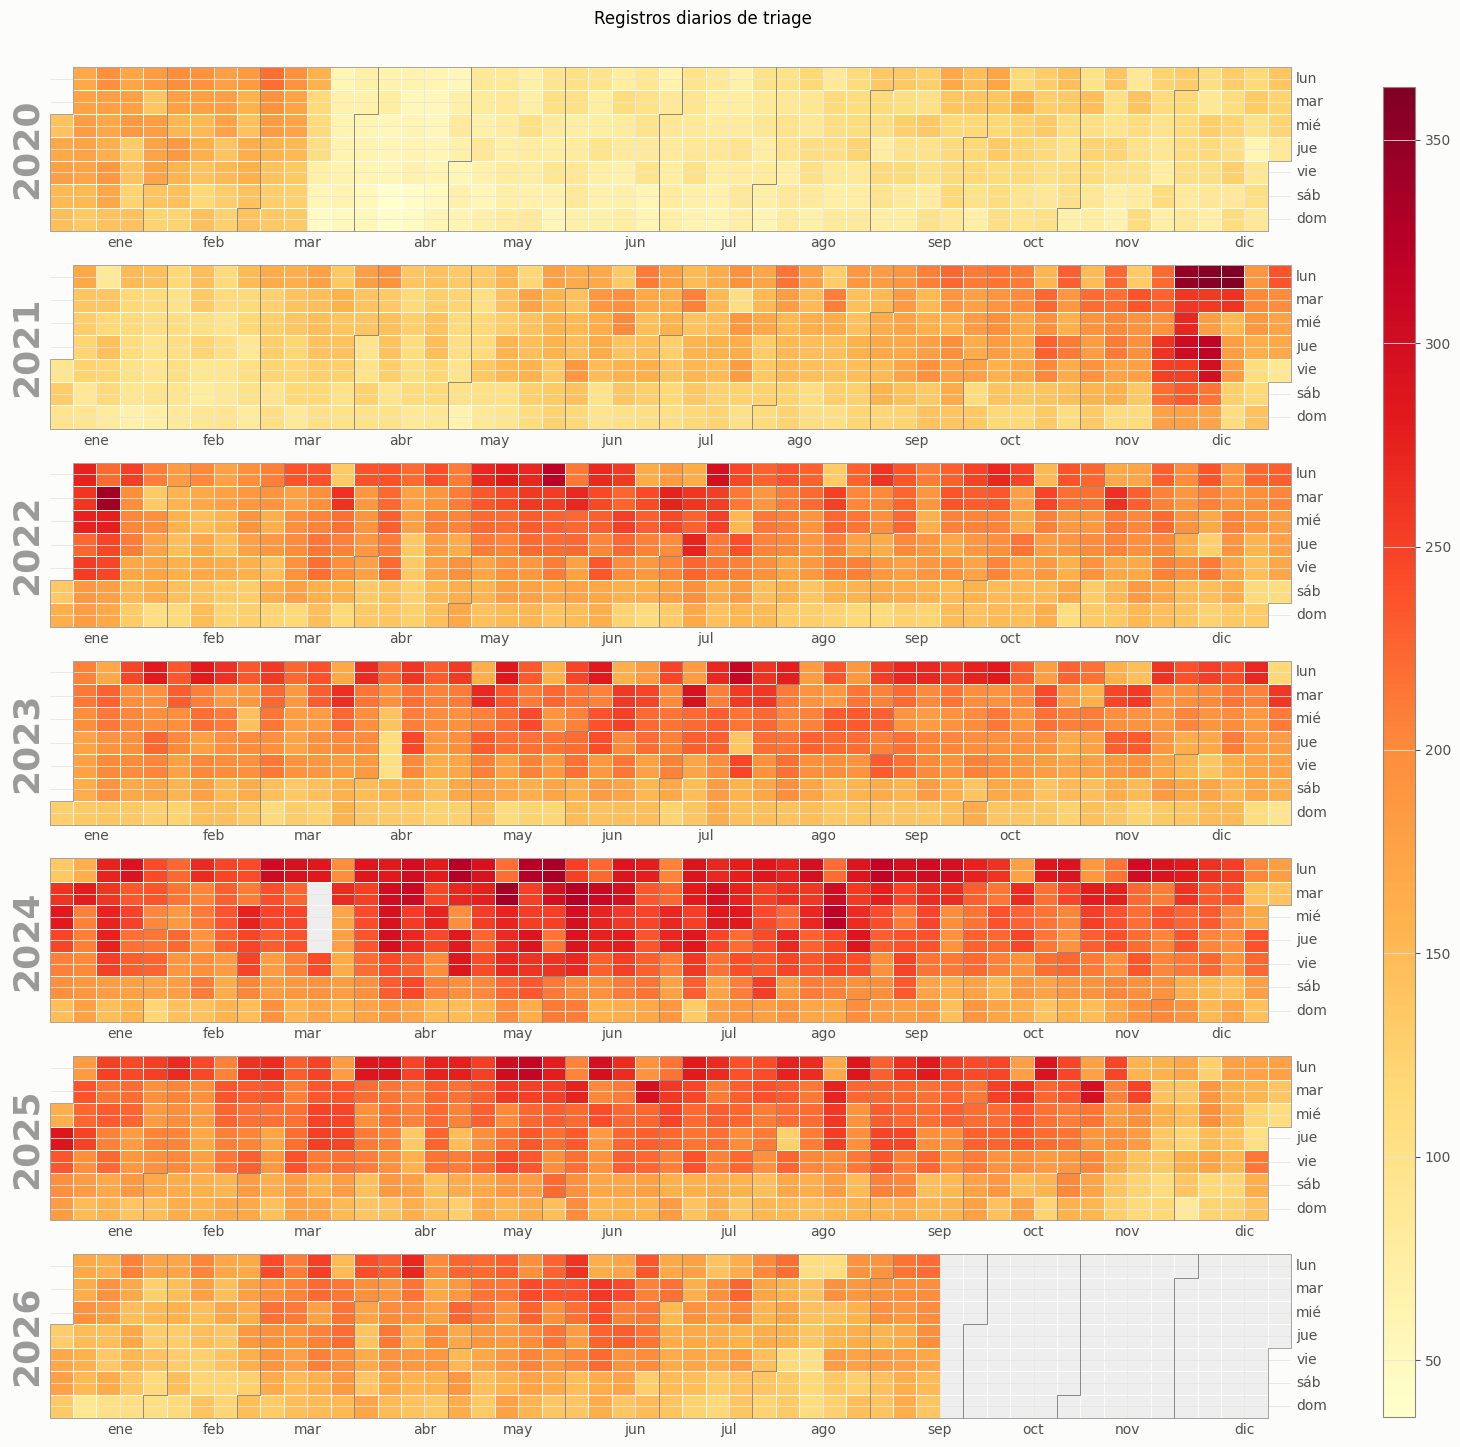

In [5]:
import calplot

calplot.calplot(serie, how=None, cmap="YlOrRd", fillcolor="#eeeeee", linewidth=0.5,
                figsize=(16, 2.0 * serie.index.year.nunique()), suptitle="Registros diarios de triage",
                yearlabel_kws={"fontname": "DejaVu Sans", "fontsize": 26, "color": "#9a9a9a"}, colorbar=True,
                daylabels=["lun", "mar", "mié", "jue", "vie", "sáb", "dom"],
                monthlabels=["ene", "feb", "mar", "abr", "may", "jun", "jul", "ago", "sep", "oct", "nov", "dic"])
plt.show()

A partir de la gráfica anterior se observa la estructura que el resto del cuaderno usa como punto de partida: las
columnas de los lunes más oscuras que las de los fines de semana en todos los años, el hueco de la COVID en 2020, el
ascenso hasta 2024 y el descenso posterior, que se explica por la salida de los afiliados de Nueva EPS. La figura
siguiente resume la misma serie por mes y por semana.

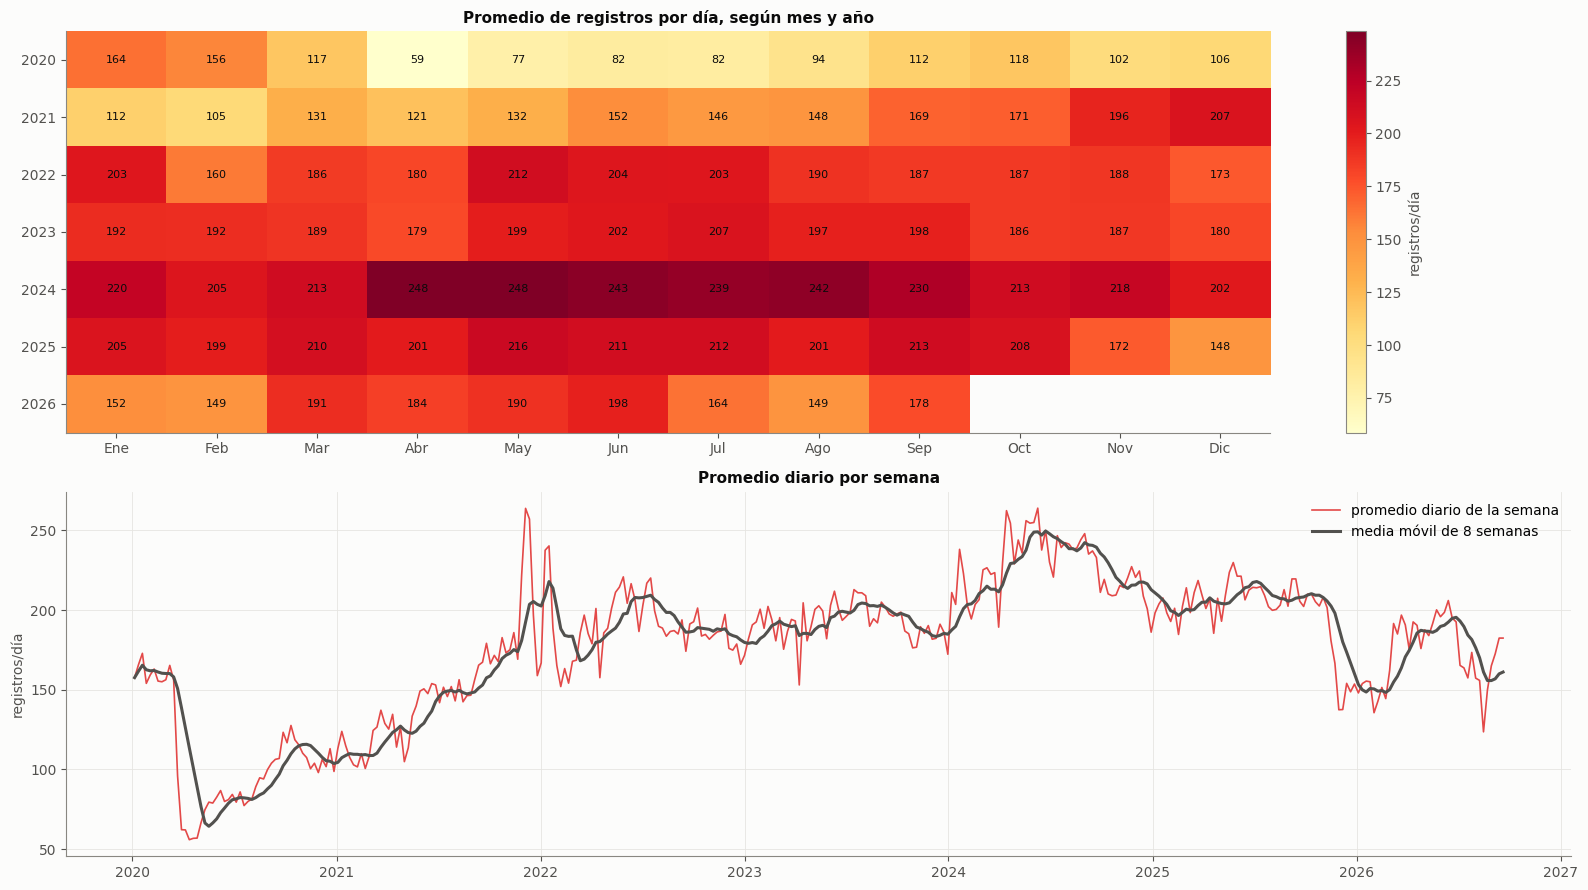

In [6]:
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(16, 9), gridspec_kw={"height_ratios": [1.1, 1]})
matriz = serie.groupby([serie.index.year, serie.index.month]).mean().unstack().reindex(columns=range(1, 13))
matriz.columns = ["Ene", "Feb", "Mar", "Abr", "May", "Jun", "Jul", "Ago", "Sep", "Oct", "Nov", "Dic"]
im = ax1.imshow(matriz.values, cmap="YlOrRd", aspect="auto")
ax1.set_xticks(range(12), matriz.columns); ax1.set_yticks(range(len(matriz)), matriz.index); ax1.grid(False)
ax1.set_title("Promedio de registros por día, según mes y año")
fig.colorbar(im, ax=ax1, label="registros/día")
for i in range(matriz.shape[0]):
    for j in range(matriz.shape[1]):
        v = matriz.values[i, j]
        if pd.notna(v): ax1.text(j, i, f"{v:.0f}", ha="center", va="center", fontsize=8, color=TINTA)
semanal = serie.resample("W").mean()
ax2.plot(semanal.index, semanal.values, lw=1.2, color=ROJO, label="promedio diario de la semana")
ax2.plot(semanal.index, semanal.rolling(8, min_periods=1).mean(), lw=2.2, color=TINTA2, label="media móvil de 8 semanas")
ax2.set_title("Promedio diario por semana"); ax2.set_ylabel("registros/día"); ax2.legend()
plt.tight_layout(); plt.show()

---
# 3. La prueba: entrenar hasta 2025 y predecir septiembre de 2026 completo

## La decisión

Una predicción hecha con datos de la víspera se apoya sobre todo en la memoria reciente: el nivel de las últimas
cuatro semanas y el desvío de los últimos días. Con ese apoyo cualquier modelo acierta una semana tranquila, y el
acierto no dice si el modelo entendió algo del hospital. Por eso se diseñó una prueba más exigente:

- **El modelo se entrena solo con el triage hasta el 31 de diciembre de 2025.** Nada de 2026 entra al
  entrenamiento.
- **Predice de una vez cada día de septiembre de 2026, del 1 al 30**, con 244 a 273 días de adelanto y sin
  reentrenar. Los días del 21 al 30 todavía no están en el archivo de entrenamiento; se verifican con la base.
- **Las variables son las del modelo vigente de la respuesta semanal (M3s)**, con una excepción: **el terremoto
  queda fuera**. En este diseño el terremoto no puede influir de ninguna forma: el único con daños en Manizales es el
  del 10 de agosto de 2026, posterior a todo el entrenamiento, y su ventana de efecto (días 0 a 21) termina el 31 de
  agosto, antes de septiembre. Quitarlo deja explícito que la predicción no depende de él.
- **Lo que no se puede saber el 31 de diciembre entra como año típico.** Salud pública, seguridad y paros de
  septiembre no se conocen en diciembre; usar su valor observado sería darle al modelo el futuro. Lo programado
  (calendario, festivos, Feria, fiestas de la región) sí entra con su valor, y el estado de la red de aseguradores
  se congela en el que tenía al cierre de 2025.

El mismo diseño se aplicó antes a septiembre de 2023, 2024 y 2025, cada uno con su modelo entrenado hasta el 31 de
diciembre anterior. Esos tres septiembres no se usaron para elegir nada: sirven para medir qué tan confiable es el
rango y la probabilidad que el modelo entrega con tanto adelanto. La configuración quedó escrita antes de calcular.

In [7]:
import pronostico as pr, mecanismos as mc, semana as sm, mes_a_ciegas as mac
import statsmodels.api   # se importa antes: al importarse reinstala su filtro de avisos
from scipy.stats import norm
ORIGEN, FECHAS = mac.ventana(ANIO)
y_ent, cal_ent = mac.datos("m3s_ciego", FECHAS[-1])
ent = y_ent.loc[:ORIGEN]
crudo = arch.reindex(ent.index)
covid = (ent.index >= pr.COVID["es_covid_fuerte"][0]) & (ent.index <= pr.COVID["es_covid_fuerte"][1])
caida = ent.index.isin(pd.date_range("2024-03-19", "2024-03-21"))
T = pd.DataFrame({"año": ent.index.year, "usado": ent.notna(), "covid": covid, "caida": caida,
                  "registros": ent.fillna(0), "en la base": crudo.fillna(0)})
R = T.groupby("año").agg(**{"días": ("usado", "size"), "días usados": ("usado", "sum"),
                            "fuera: COVID fuerte": ("covid", "sum"), "fuera: caída de registro": ("caida", "sum"),
                            "registros en la base": ("en la base", "sum"), "registros usados": ("registros", "sum")})
R.loc["total"] = R.sum()
R["media por día usado"] = (R["registros usados"] / R["días usados"]).round(1)
R.index = R.index.astype(str)
display(R.astype({c: int for c in R.columns if c != "media por día usado"}).style.format(thousands=".", decimal=",", precision=1)
        .set_caption(f"Registros con que se entrenó el modelo: {ent.index.min().date()} a {ORIGEN.date()}"))

,días,días usados,fuera: COVID fuerte,fuera: caída de registro,registros en la base,registros usados,media por día usado
año,,,,,,,
2020,366,196,170,0,38.682,25.218,"128,7"
2021,365,365,0,0,54.509,54.509,"149,3"
2022,365,365,0,0,69.217,69.217,"189,6"
2023,365,365,0,0,70.220,70.220,"192,4"
2024,366,363,0,3,82.397,82.357,"226,9"
2025,365,365,0,0,72.867,72.867,"199,6"
total,2.192,2.019,170,3,387.892,374.388,"185,4"


La tabla anterior resume lo que vio el modelo. Quedan fuera la fase fuerte de la COVID (del 15 de marzo al 31 de
agosto de 2020), porque enseña una forma del año que no es la del hospital, y los tres días de marzo de 2024 en que
falló el registro. Todo lo demás, de 2020 a 2025, entra. La tabla siguiente lista las variables y cómo entra cada
una cuando se predice septiembre.

In [8]:
PAS, FUT = pr.contexto_exp(cal_ent.index)
cols = [c for c in pr.calendario(cal_ent.index, cal_ent)] + ["nivel", "mem_semana", "mem_ultimo", "mem_mismo_dia"] + list(FUT) + list(PAS)
GRUPOS = [("Día de la semana", "dow_", "conocida por adelantado"),
          ("Calendario (festivos, puentes, quincena, vacaciones, temporadas)", "es_", "conocida por adelantado"),
          ("Estación del año (3 armónicos)", "four_", "conocida por adelantado"),
          ("Nivel de los 28 días previos", "nivel", "el del 31 de diciembre de 2025"),
          ("Memoria de corto plazo", "mem_", "la del 31 de diciembre de 2025"),
          ("Eventos programados (Feria, noches festivas, día siguiente, fiestas a ≥ 60 km)", "fut_m_", "conocida por adelantado"),
          ("Salud pública de la ciudad (con compuerta)", "ext_g_m_sal_", "LightGBM: la del origen; SARIMAX: no entra"),
          ("Red de aseguradores (con compuerta)", "ext_g_m_red_", "LightGBM: la del origen; SARIMAX: no entra"),
          ("Seguridad, MinDefensa (con compuerta)", "ext_g_m_soc_", "LightGBM: la del origen; SARIMAX: no entra"),
          ("Paro nacional de 2021", "ext_m_paro", "año típico (0)")]
V = [{"grupo": g, "columnas": sum(c.startswith(p) for c in cols), "cómo entra en septiembre": como} for g, p, como in GRUPOS]
V += [{"grupo": "Terremoto (catástrofe, semanas 1 a 3)", "columnas": 0, "cómo entra en septiembre": "fuera, por decisión"},
      {"grupo": "Clima de rezago corto (7 a 21 días)", "columnas": 0, "cómo entra en septiembre": "fuera: no se conoce con meses de adelanto"}]
display(pd.DataFrame(V).set_index("grupo"))
assert not any(c.startswith("ext_m_catastrofe") for c in cols), "el terremoto no debe entrar"

,columnas,cómo entra en septiembre
grupo,,
Día de la semana,6,conocida por adelantado
"Calendario (festivos, puentes, quincena, vacaciones, temporadas)",12,conocida por adelantado
Estación del año (3 armónicos),6,conocida por adelantado
Nivel de los 28 días previos,1,el del 31 de diciembre de 2025
Memoria de corto plazo,3,la del 31 de diciembre de 2025
"Eventos programados (Feria, noches festivas, día siguiente, fiestas a ≥ 60 km)",4,conocida por adelantado
Salud pública de la ciudad (con compuerta),5,LightGBM: la del origen; SARIMAX: no entra
Red de aseguradores (con compuerta),6,LightGBM: la del origen; SARIMAX: no entra
"Seguridad, MinDefensa (con compuerta)",2,LightGBM: la del origen; SARIMAX: no entra


---
# 4. Qué tan confiable es: el mismo diseño en septiembre de 2023, 2024 y 2025

Antes de mirar 2026 se mide el diseño donde ya se conoce la respuesta. Para cada año, el modelo se entrenó hasta el
31 de diciembre anterior y predijo los 30 días de septiembre. Se comparan cuatro predicciones:

- **M3s**: el modelo vigente (SARIMAX y LightGBM con los mecanismos externos), sin el terremoto.
- **C0r**: la misma combinación sin contexto externo, solo calendario, estación, nivel y memoria.
- **Lo normal**: la regresión de calendario y estación con el nivel del 31 de diciembre. Es el control: lo que se
  anunciaría sin modelo.
- **El año pasado**: el mismo día de la semana de hace 52 semanas.

Las medidas son el error medio del día, la proporción de días dentro del rango del 80 % (lo ideal es cerca del
80 %), el acierto en si el día queda por encima o por debajo de lo normal, y las mismas medidas para la media de
cada semana. El rango de la semana sale de simular las semanas posibles respetando la correlación entre días
consecutivos que se midió en estos tres septiembres.

In [9]:
P = mac.leer()
P["semana"] = P.fecha - pd.to_timedelta(P.fecha.dt.dayofweek, unit="D")
N = P[P.modelo == "normal"].set_index(["anio", "fecha"]).q50.rename("normal")
P = P.join(N, on=["anio", "fecha"])
P["p_sube"] = np.nan
for m in ["M3s", "C0r"]:
    k = P.modelo == m; P.loc[k, "p_sube"] = pr.prob_sobre(P.loc[k, pr.QCOL].values, P.loc[k, "normal"].values)
VAL = P[(P.anio < ANIO)].dropna(subset=["real"])
MOD = {"M3s": "M3s", "C0r": "C0r", "normal": "lo normal", "anio_pasado": "el año pasado"}

def rho_de(G):
    # correlación del error entre días consecutivos (en escala normal), promedio de los septiembres
    r = []
    for _, g in G.groupby("anio"):
        z = norm.ppf(sm.pit(g[pr.QCOL].values, g.real.values)); r.append(np.corrcoef(z[:-1], z[1:])[0, 1])
    return float(np.mean(r))
RHO = {m: rho_de(VAL[VAL.modelo == m]) for m in MOD}

def semanas(G, rho):
    filas = []
    for (a, s), g in G.groupby(["anio", "semana"]):
        if g.real.isna().any(): continue
        sim = sm.semana_agregada(g[pr.QCOL].values, rho)
        filas.append({"anio": a, "semana": s, "días": len(g), "real": g.real.mean(), "q10": np.quantile(sim, .1),
                      "q50": np.quantile(sim, .5), "q90": np.quantile(sim, .9), "normal": g.normal.mean(),
                      "p_normal": (sim > g.normal.mean()).mean()})
    return pd.DataFrame(filas)

filas = []
for m, nombre in MOD.items():
    G = VAL[VAL.modelo == m]; W = semanas(G, RHO[m])
    dice = G.p_sube > .5 if m in ("M3s", "C0r") else (G.q50 > G.normal if m == "anio_pasado" else None)
    filas.append({"predicción": nombre,
        "error medio del día %": 100 * np.mean(np.abs(G.q50 - G.real) / G.real),
        "sesgo %": 100 * np.mean((G.q50 - G.real) / G.real),
        "días dentro del rango 80 %": 100 * np.mean((G.real >= G.q10) & (G.real <= G.q90)),
        "acierto sube/baja %": 100 * np.mean(dice == (G.real > G.normal)) if dice is not None else np.nan,
        "días que de verdad subieron %": 100 * np.mean(G.real > G.normal),
        "error de la media semanal %": 100 * np.mean(np.abs(W.q50 - W.real) / W.real),
        "semanas dentro del rango 80 %": 100 * np.mean((W.real >= W.q10) & (W.real <= W.q90)),
        "rho entre días": RHO[m]})
CONF = pd.DataFrame(filas).set_index("predicción")
display(CONF.style.format(precision=1, na_rep="—").format("{:.2f}", subset=["rho entre días"])
        .set_caption("Septiembre de 2023, 2024 y 2025, cada uno predicho desde el 31 de diciembre anterior (90 días, 15 semanas)"))
POR_ANIO = VAL[VAL.modelo.isin(["M3s", "C0r", "normal"])].groupby(["anio", "modelo"]).apply(
    lambda G: pd.Series({"error del día %": 100 * np.mean(np.abs(G.q50 - G.real) / G.real),
                         "media real": G.real.mean(), "media predicha": G.q50.mean(),
                         "días en rango %": 100 * np.mean((G.real >= G.q10) & (G.real <= G.q90))})).unstack("modelo")
display(POR_ANIO.round(1))

,error medio del día %,sesgo %,días dentro del rango 80 %,acierto sube/baja %,días que de verdad subieron %,error de la media semanal %,semanas dentro del rango 80 %,rho entre días
predicción,,,,,,,,
M3s,11.3,-8.5,75.6,60.0,85.6,11.4,56.2,0.14
C0r,11.4,-9.3,87.8,60.0,85.6,11.1,68.8,0.17
lo normal,11.2,-9.9,62.2,—,85.6,11.2,18.8,0.12
el año pasado,26.3,25.0,93.3,85.6,85.6,28.5,37.5,0.14


error del día %              media real               media predicha  \
modelo             C0r   M3s normal        C0r    M3s normal            C0r   
anio                                                                          
2023              10.1   9.6    9.0      197.5  197.5  197.5          176.9   
2024              17.8  18.1   17.6      229.6  229.6  229.6          186.5   
2025               6.2   6.1    7.0      212.8  212.8  212.8          209.0   

                     días en rango %               
modelo    M3s normal             C0r   M3s normal  
anio                                               
2023    178.6  179.0            96.7  90.0   80.0  
2024    186.2  187.3            66.7  43.3   26.7  
2025    212.2  203.4           100.0  93.3   80.0

De las tablas anteriores se puede interpretar lo siguiente. **Con ocho meses de adelanto, el modelo no le gana al
control de calendario en el error del día**: en los tres septiembres, M3s, C0r y lo normal quedan en torno al 11 %.
Lo que sí aporta el modelo es un rango mejor calibrado (76 % de días dentro, frente a 62 % de lo normal). 2024 es el
año difícil: el volumen subió hasta su máximo histórico durante ese año, y desde diciembre de 2023 no había forma de
anticiparlo.

**El acierto en sube/baja no sirve en esta prueba**, y la columna de días que de verdad subieron explica por qué. Lo
normal se calcula con el nivel de diciembre, que es bajo por la temporada navideña, y queda sistemáticamente por
debajo de septiembre (sesgo del −10 %). Contra una vara tan baja casi todos los días «suben», y decir siempre que sube
acierta más que cualquier modelo: eso es lo que hace el año pasado. Por eso, en esta prueba, las medidas que cuentan
son el error y el rango, no la probabilidad de subir.

**El rango de la semana promete más de lo que cumple**: solo el 56 % de las semanas de M3s quedaron dentro de su rango
del 80 %. El error de un pronóstico a ocho meses es sobre todo de nivel y se repite en todos los días de la semana,
y la correlación entre días consecutivos (rho) no lo recoge del todo, de modo que el rango semanal sale demasiado
estrecho.

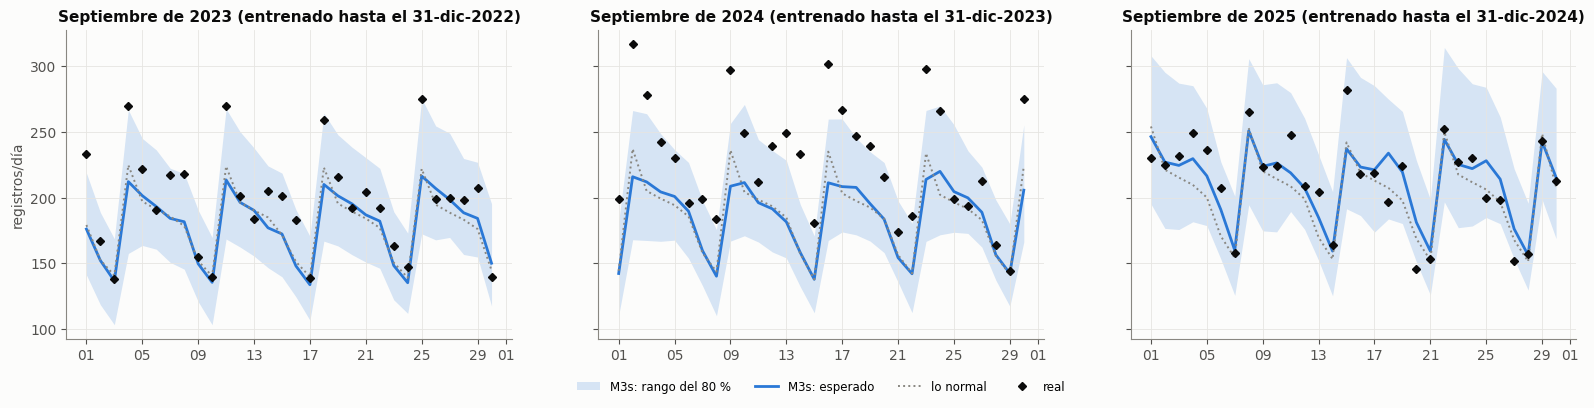

In [10]:
fig, axs = plt.subplots(1, 3, figsize=(16, 4.2), sharey=True)
for ax, (a, G) in zip(axs, VAL[VAL.modelo == "M3s"].groupby("anio")):
    ax.fill_between(G.fecha, G.q10, G.q90, color=AZUL, alpha=.18, lw=0, label="M3s: rango del 80 %")
    ax.plot(G.fecha, G.q50, color=AZUL, lw=2, label="M3s: esperado")
    ax.plot(G.fecha, G.normal, color=MUDO, lw=1.4, ls=":", label="lo normal")
    ax.plot(G.fecha, G.real, color=TINTA, marker="D", ms=4, lw=0, label="real")
    ax.set_title(f"Septiembre de {a} (entrenado hasta el 31-dic-{a - 1})")
    ax.xaxis.set_major_formatter(plt.matplotlib.dates.DateFormatter("%d"))
axs[0].set_ylabel("registros/día")
axs[1].legend(ncol=4, fontsize=8.5, loc="upper center", bbox_to_anchor=(.5, -.1))
plt.tight_layout(); plt.show()

En cada panel, la franja azul es el rango del 80 % que el modelo anunció ocho meses antes y los rombos negros son
lo ocurrido. Un rango bien calibrado deja fuera unos 6 de los 30 días; uno que deja fuera muchos más promete una
seguridad que no tiene, y uno que no deja fuera ninguno es tan ancho que no informa.

---
# 5. La predicción de septiembre de 2026

Con el modelo entrenado hasta el 31 de diciembre de 2025 se predice cada día de septiembre de 2026. La predicción es
la misma que se habría escrito el 1 de enero: no se reentrenó con ningún dato de 2026.

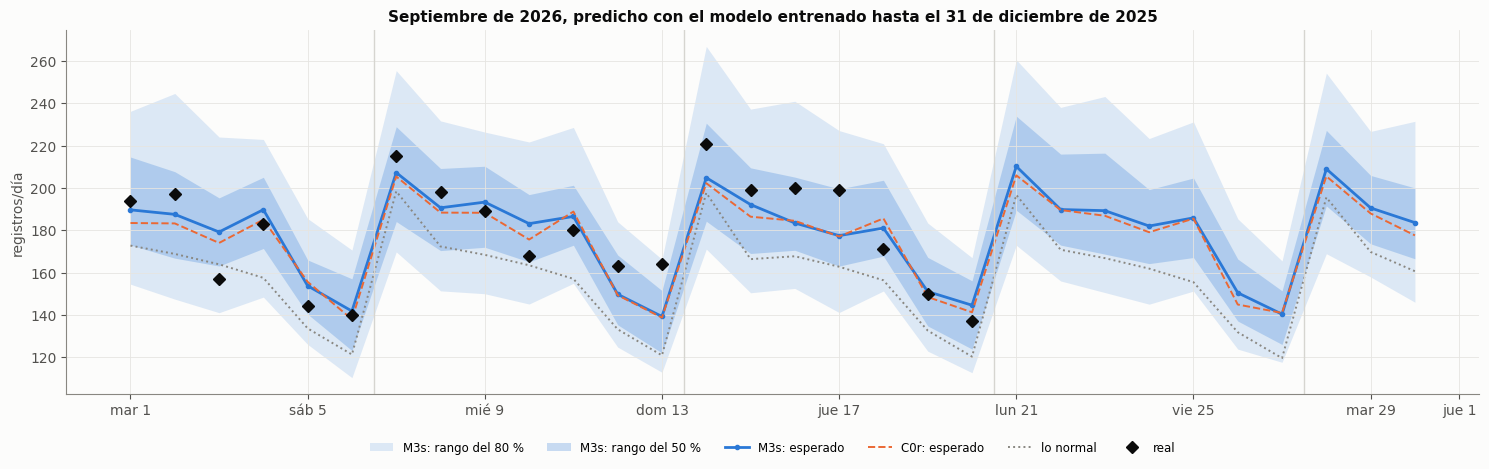

Días de septiembre con registro real en la fuente: 20 de 30.


In [11]:
Z = P[P.anio == ANIO].copy()
real = serie.reindex(FECHAS)                                  # lo ocurrido, de la fuente de la sección 1
Z["real"] = real.reindex(Z.fecha).values
D = {m: Z[Z.modelo == m].set_index("fecha") for m in MOD}
M3, C0, NO = D["M3s"], D["C0r"], D["normal"]

fig, ax = plt.subplots(figsize=(15, 4.8))
ax.fill_between(M3.index, M3.q10, M3.q90, color=AZUL, alpha=.15, lw=0, label="M3s: rango del 80 %")
ax.fill_between(M3.index, M3.q25, M3.q75, color=AZUL, alpha=.25, lw=0, label="M3s: rango del 50 %")
ax.plot(M3.index, M3.q50, color=AZUL, lw=2, marker="o", ms=3, label="M3s: esperado")
ax.plot(C0.index, C0.q50, color=NARANJA, lw=1.4, ls="--", label="C0r: esperado")
ax.plot(NO.index, NO.q50, color=MUDO, lw=1.4, ls=":", label="lo normal")
ax.plot(real.index, real.values, color=TINTA, marker="D", ms=6, lw=0, label="real")
for s in pd.date_range(FECHAS[0] - pd.Timedelta(days=FECHAS[0].dayofweek), FECHAS[-1], freq="7D")[1:]:
    ax.axvline(s - pd.Timedelta(hours=12), color="#d6d5d0", lw=1)
ax.set_title(f"Septiembre de {ANIO}, predicho con el modelo entrenado hasta el 31 de diciembre de {ANIO - 1}")
ax.set_ylabel("registros/día"); ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: (lambda t: f"{DIAS[t.dayofweek][:3]} {t.day}")(pd.Timestamp(plt.matplotlib.dates.num2date(v)))))
ax.legend(ncol=6, fontsize=8.5, loc="upper center", bbox_to_anchor=(.5, -.1))
plt.tight_layout(); plt.show()
print(f"Días de septiembre con registro real en la fuente: {int(real.notna().sum())} de {len(FECHAS)}.")

Las líneas verticales separan las semanas, de lunes a domingo. Los rombos negros son los días que la fuente ya
tiene; donde no hay rombo, la predicción espera el dato.

---
# 6. Lo predicho frente a lo ocurrido

La primera tabla compara cada día de septiembre: el valor esperado y su rango, el registro real, el error, y si el
modelo acertó que el día quedaría por encima o por debajo de lo normal. La segunda compara cada semana, de lunes a
domingo: la media diaria anunciada con su rango y la media real. La primera y la última semana del mes son
parciales (del martes 1 al domingo 6 y del lunes 28 al miércoles 30).

In [12]:
sino = lambda b: np.where(b, "sí", "no")
hay = real.notna().values
T = pd.DataFrame({
    "día": [fecha_larga(t) for t in FECHAS],
    "predicho M3s": M3.q50.round().astype(int).values,
    "rango 80 %": [f"{a:.0f}-{b:.0f}" for a, b in zip(M3.q10, M3.q90)],
    "real": [f"{v:.0f}" if h else "sin dato" for v, h in zip(real.values, hay)],
    "¿dentro del rango?": np.where(hay, sino((real.values >= M3.q10.values) & (real.values <= M3.q90.values)), "—"),
    "error %": [f"{100 * (p - r) / r:+.1f}" if h else "—" for p, r, h in zip(M3.q50.values, real.values, hay)],
    "lo normal": NO.q50.round().astype(int).values,
    "P(sube)": [f"{100 * p:.0f} %" for p in M3.p_sube],
    "¿subió?": np.where(hay, sino(real.values > NO.q50.values), "—"),
    "¿acertó?": np.where(hay, np.where((M3.p_sube.values > .5) == (real.values > NO.q50.values), "✔", "✘"), "—"),
    "predicho C0r": C0.q50.round().astype(int).values}).set_index("día")
display(T)

,predicho M3s,rango 80 %,real,¿dentro del rango?,error %,lo normal,P(sube),¿subió?,¿acertó?,predicho C0r
día,,,,,,,,,,
martes 1 de septiembre,190,155-236,194,sí,-2.2,173,75 %,sí,✔,183
miércoles 2 de septiembre,188,147-245,197,sí,-4.8,169,73 %,sí,✔,183
jueves 3 de septiembre,179,141-224,157,sí,+14.1,164,74 %,no,✘,174
viernes 4 de septiembre,190,148-223,183,sí,+3.7,158,84 %,sí,✔,185
sábado 5 de septiembre,154,126-186,144,sí,+6.8,134,82 %,sí,✔,156
domingo 6 de septiembre,142,110-171,140,sí,+1.3,121,77 %,sí,✔,138
lunes 7 de septiembre,207,170-256,215,sí,-3.6,198,60 %,sí,✔,205
martes 8 de septiembre,191,151-232,198,sí,-3.7,172,73 %,sí,✔,188
miércoles 9 de septiembre,193,150-226,189,sí,+2.3,168,77 %,sí,✔,188


La columna P(sube) es alta en casi todos los días porque lo normal, calculado con el nivel de diciembre, queda por
debajo de septiembre (sección 4). Se muestra para que la tabla tenga la misma forma que la respuesta semanal, pero
en esta prueba la lectura útil es la del valor predicho, su rango y el error.

In [13]:
DIAS_CORTOS = ["lun", "mar", "mié", "jue", "vie", "sáb", "dom"]
filas = []
for s, g in M3.groupby(M3.index - pd.to_timedelta(M3.index.dayofweek, unit="D")):
    f = g.index; sim = sm.semana_agregada(g[pr.QCOL].values, RHO["M3s"])
    r = real.reindex(f); nr = NO.q50.reindex(f).mean(); simc = sm.semana_agregada(C0.loc[f, pr.QCOL].values, RHO["C0r"])
    completa = r.notna().all()
    filas.append({"semana": f"{DIAS_CORTOS[f[0].dayofweek]} {f[0].day} a {DIAS_CORTOS[f[-1].dayofweek]} {f[-1].day}",
                  "días": len(f), "media predicha M3s": np.quantile(sim, .5),
                  "rango 80 %": f"{np.quantile(sim, .1):.0f}-{np.quantile(sim, .9):.0f}",
                  "media real": f"{r.mean():.1f}" if completa else (f"{r.mean():.1f} ({int(r.notna().sum())} días)" if r.notna().any() else "sin dato"),
                  "¿dentro del rango?": sino(np.quantile(sim, .1) <= r.mean() <= np.quantile(sim, .9)).item() if completa else "—",
                  "error %": f"{100 * (np.quantile(sim, .5) - r.mean()) / r.mean():+.1f}" if completa else "—",
                  "lo normal": nr, "P(sobre lo normal)": f"{100 * (sim > nr).mean():.0f} %",
                  "¿quedó sobre lo normal?": sino(r.mean() > nr).item() if completa else "—",
                  "media predicha C0r": np.quantile(simc, .5)})
TS = pd.DataFrame(filas).set_index("semana")
display(TS.style.format(precision=1))

,días,media predicha M3s,rango 80 %,media real,¿dentro del rango?,error %,lo normal,P(sobre lo normal),¿quedó sobre lo normal?,media predicha C0r
semana,,,,,,,,,,
mar 1 a dom 6,6,174.7,158-193,169.2,sí,+3.3,153.0,95 %,sí,171.3
lun 7 a dom 13,7,179.6,164-195,182.4,sí,-1.6,159.1,96 %,sí,177.0
lun 14 a dom 20,7,179.3,163-196,182.4,sí,-1.7,157.7,96 %,sí,176.4
lun 21 a dom 27,7,181.0,165-197,sin dato,—,—,157.6,97 %,—,177.9
lun 28 a mié 30,3,195.5,172-222,sin dato,—,—,175.3,86 %,—,191.7


In [14]:
def parrafo():
    h = real.notna(); r = real[h].values; q = M3.q50[h].values
    m, mp = r.mean(), q.mean(); dentro = int(((r >= M3.q10[h].values) & (r <= M3.q90[h].values)).sum())
    acierto = int(((M3.p_sube[h].values > .5) == (r > NO.q50[h].values)).sum()); subieron = int((r > NO.q50[h].values).sum())
    e = 100 * np.mean(np.abs(q - r) / r); sesgo = 100 * np.mean((q - r) / r)
    e_no = 100 * np.mean(np.abs(NO.q50[h].values - r) / r); e_c0 = 100 * np.mean(np.abs(C0.q50[h].values - r) / r)
    e_ap = 100 * np.mean(np.abs(D["anio_pasado"].q50[h].values - r) / r)
    forma = np.corrcoef(q, r)[0, 1]; nivel = float(serie[ORIGEN - pd.Timedelta(days=27):ORIGEN].mean())
    v = CONF.loc["M3s"]
    L = [f"**Lo ocurrido.** De los {len(FECHAS)} días de septiembre de {ANIO}, la fuente tiene {int(h.sum())}. En ellos la media fue "
         f"de {num(m)} registros por día; el modelo, entrenado hasta el 31 de diciembre, había anunciado {num(mp)} para esos mismos días.",
         f"**Acierto.** El error medio del día fue del {num(e)} % ({'sobreestimando' if sesgo > 0 else 'subestimando'} en promedio un "
         f"{num(abs(sesgo))} %). Cayeron dentro del rango del 80 % {dentro} de {int(h.sum())} días ({num(100 * dentro / h.sum(), 0)} %), y la "
         f"dirección frente a lo normal se acertó en {acierto} de {int(h.sum())}, aunque {subieron} de esos días quedaron por encima de lo normal, "
         f"así que decir siempre «sube» habría acertado lo mismo o más. En los tres septiembres de validación el mismo diseño "
         f"dio un error del {num(v['error medio del día %'])} %, el {num(v['días dentro del rango 80 %'], 0)} % de días dentro del rango "
         f"y un {num(v['semanas dentro del rango 80 %'], 0)} % de semanas dentro de su rango: ese es el desempeño que se puede esperar del "
         f"modelo con ocho meses de adelanto. {'Septiembre de 2026 salió mejor que esa expectativa; con un solo mes no se puede separar el acierto de la suerte.' if e < v['error medio del día %'] else ''}",
         f"**Frente a las bases.** En los mismos días, lo normal se equivocó un {num(e_no)} %, C0r un {num(e_c0)} % y el mismo día del año "
         f"pasado un {num(e_ap)} %."]
    por = [f"la forma del mes {'se reprodujo' if forma >= .7 else 'no se reprodujo del todo'} (correlación de {num(forma, 2)} entre "
           f"lo anunciado y lo ocurrido día a día){', y esa parte la aporta el calendario' if forma >= .7 else ''}"]
    por.append(f"el nivel de partida era el del cierre de 2025 ({num(nivel)} registros por día en las cuatro semanas previas al origen, "
               f"temporada navideña incluida), y el modelo lo traslada a septiembre con la estación aprendida de los años anteriores")
    if abs(sesgo) >= 5:
        por.append(f"el sesgo del {num(sesgo)} % indica que el nivel de la red cambió durante 2026 de una forma que el 31 de diciembre "
                   f"no se podía saber")
    L.append("**Por qué.** Se observa que " + "; ".join(por) + ".")
    return "\n\n".join(L)
display(Markdown(parrafo()))

**Lo ocurrido.** De los 30 días de septiembre de 2026, la fuente tiene 20. En ellos la media fue de 178,4 registros por día; el modelo, entrenado hasta el 31 de diciembre, había anunciado 176,3 para esos mismos días.

**Acierto.** El error medio del día fue del 6,0 % (subestimando en promedio un 0,7 %). Cayeron dentro del rango del 80 % 20 de 20 días (100 %), y la dirección frente a lo normal se acertó en 19 de 20, aunque 19 de esos días quedaron por encima de lo normal, así que decir siempre «sube» habría acertado lo mismo o más. En los tres septiembres de validación el mismo diseño dio un error del 11,3 %, el 76 % de días dentro del rango y un 56 % de semanas dentro de su rango: ese es el desempeño que se puede esperar del modelo con ocho meses de adelanto. Septiembre de 2026 salió mejor que esa expectativa; con un solo mes no se puede separar el acierto de la suerte.

**Frente a las bases.** En los mismos días, lo normal se equivocó un 12,5 %, C0r un 6,2 % y el mismo día del año pasado un 35,2 %.

**Por qué.** Se observa que la forma del mes se reprodujo (correlación de 0,86 entre lo anunciado y lo ocurrido día a día), y esa parte la aporta el calendario; el nivel de partida era el del cierre de 2025 (147,3 registros por día en las cuatro semanas previas al origen, temporada navideña incluida), y el modelo lo traslada a septiembre con la estación aprendida de los años anteriores.

---
# 7. Límites del análisis

- **Es una prueba de lo que el modelo sabe sin datos recientes, no de su uso semanal.** En operación el modelo se
  reentrena cada semana con el triage al día; aquí no, a propósito. Su error con ocho meses de adelanto es la cota
  pesimista de lo que el modelo sabe del hospital.
- **El contexto externo no puede ayudar con tanto adelanto.** Lo que el modelo no conoce el 31 de diciembre entra
  como año típico, de modo que la diferencia entre M3s y C0r aquí sale casi solo de los eventos programados y del
  entrenamiento sin la fase fuerte de la COVID.
- **El nivel de la red se congela en el origen.** Un cambio posterior en el volumen de un asegurador (como la salida
  de los afiliados de Nueva EPS en julio de 2026) no se puede anticipar desde diciembre.
- **El rango de la semana es demasiado estrecho a este adelanto.** En la validación cubrió el 56 % de las semanas,
  no el 80 %; el rango de cada día sí está cerca de lo prometido (76 %).
- **La probabilidad de subir no informa en esta prueba**, porque lo normal se calcula con el nivel de diciembre y
  queda por debajo de septiembre.
- **Tres septiembres son 90 días y 15 semanas.** Los porcentajes de confiabilidad tienen la incertidumbre de una
  muestra pequeña: una diferencia de pocos puntos entre modelos no es concluyente.
- **Los días sin dato.** Mientras la fuente no tenga los últimos días del mes, la comparación es parcial; la
  conexión con la base de la sección 1 los completa.